# การตรวจจับขอบภาพ (Edge Detection)

บทเรียนนี้อธิบายแนวคิดพื้นฐานของการตรวจจับขอบภาพ พร้อมตัวอย่างโค้ด Python/OpenCV ที่กระชับ เหมาะสำหรับการสอนนักศึกษาปริญญาตรี

**เป้าหมายการเรียนรู้**

- อธิบายได้ว่า “ขอบภาพ” คือบริเวณที่ค่าความเข้มของภาพเปลี่ยนอย่างรวดเร็ว
- เข้าใจบทบาทของ gradient, convolution kernel และขนาดของ gradient
- ทดลองใช้ Prewitt, Sobel และ Canny edge detector ได้อย่างถูกต้อง
- อ่านภาพอย่างปลอดภัย โดยตรวจสอบว่าไฟล์ภาพมีจริงและอ่านสำเร็จหรือไม่


## 1. แนวคิดสำคัญ

ภาพระดับเทา (grayscale image) มองได้เป็นฟังก์ชัน 2 มิติ `I(x, y)` โดยค่าที่ตำแหน่ง `(x, y)` คือความสว่างของพิกเซลนั้น ขอบภาพมักเกิดในบริเวณที่ค่าความสว่างเปลี่ยนเร็ว เช่น รอยต่อระหว่างวัตถุกับพื้นหลัง เส้นตัวอักษร หรือเส้นขอบของรูปร่าง

แนวคิดหลักคือหา **gradient** หรืออัตราการเปลี่ยนแปลงของความเข้มภาพในแนวแกน x และ y

$$
G_x = \frac{\partial I}{\partial x}, \quad G_y = \frac{\partial I}{\partial y}
$$

ขนาดของ gradient ใช้บอก “ความแรงของขอบ” ได้โดยประมาณ

$$
|G| = \sqrt{G_x^2 + G_y^2}
$$

ในภาพดิจิทัล เราประมาณ gradient ด้วยการทำ **convolution** ระหว่างภาพกับ kernel ขนาดเล็ก เช่น 3x3


## 2. เตรียมไลบรารี

ใช้ `OpenCV` สำหรับประมวลผลภาพ, `NumPy` สำหรับคำนวณเชิงเมทริกซ์ และ `Matplotlib` สำหรับแสดงผลใน notebook แทน `cv2.imshow()` เพราะ `cv2.imshow()` มักไม่เหมาะกับสภาพแวดล้อมแบบ Jupyter Notebook


In [14]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt


## 3. ฟังก์ชันช่วยแสดงภาพและเตรียมข้อมูล

ฟังก์ชันชุดนี้ทำให้ cell ถัด ๆ ไปอ่านง่ายขึ้น โดยมีหน้าที่หลักคือ

- แสดงภาพหลายภาพในแถวเดียวกัน
- แปลงผลลัพธ์ที่เป็นทศนิยมให้กลับมาอยู่ในช่วง 0-255
- สร้างภาพตัวอย่างสำรอง หากยังไม่มีไฟล์ภาพในโฟลเดอร์ `images`
- อ่านไฟล์ภาพอย่างปลอดภัยด้วย `try/except`


In [15]:
def show_images(images, titles=None, cmap="gray", figsize=(14, 4)):
    """แสดงภาพหลายภาพใน notebook"""
    if titles is None:
        titles = [""] * len(images)

    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles), start=1):
        plt.subplot(1, len(images), i)
        plt.imshow(img, cmap=cmap, vmin=0, vmax=255)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


def normalize_to_uint8(img):
    """ปรับค่าภาพให้อยู่ในช่วง 0-255 และแปลงเป็น uint8"""
    img = img.astype(np.float32)
    min_val, max_val = img.min(), img.max()
    if max_val == min_val:
        return np.zeros_like(img, dtype=np.uint8)
    scaled = (img - min_val) * 255.0 / (max_val - min_val)
    return scaled.astype(np.uint8)


def create_demo_image(size=256):
    """สร้างภาพตัวอย่างแบบง่ายสำหรับทดลอง edge detection"""
    img = np.full((size, size), 200, dtype=np.uint8)
    cv2.rectangle(img, (30, 40), (115, 180), 60, -1)
    cv2.circle(img, (175, 85), 42, 120, -1)
    cv2.line(img, (145, 180), (230, 220), 20, 5)
    cv2.putText(img, "EDGE", (38, 230), cv2.FONT_HERSHEY_SIMPLEX, 1.1, 0, 3)
    return img


def read_gray_image(fp):
    """อ่านภาพเป็น grayscale และแจ้ง error เมื่อไม่พบไฟล์หรืออ่านไม่ได้"""
    img = cv2.imread(str(fp), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"ไม่พบไฟล์ภาพหรือไม่สามารถอ่านไฟล์ภาพได้: {fp}")
    return img


### ตัวอย่างภาพที่สร้างด้วย `create_demo_image()`

ฟังก์ชัน `create_demo_image()` ใช้สร้างภาพระดับเทาแบบง่าย ๆ เพื่อให้ notebook ยังทดลอง edge detection ได้ แม้ยังไม่มีไฟล์ภาพจริงในโฟลเดอร์ `images`

ภาพตัวอย่างนี้ตั้งใจให้มีองค์ประกอบหลายแบบ เช่น สี่เหลี่ยม วงกลม เส้นเฉียง และตัวอักษร เพื่อให้เห็นว่าตัวตรวจจับขอบตอบสนองกับรอยต่อของความเข้มภาพอย่างไร


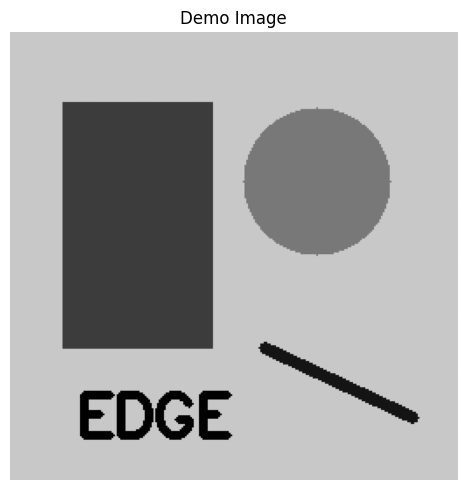

In [16]:
demo_image = create_demo_image()
show_images([demo_image], ["Demo Image"], figsize=(5, 5))


## 4. อ่านภาพตัวอย่างอย่างปลอดภัย

หลักปฏิบัติที่ดีคือหลัง `cv2.imread()` ต้องตรวจสอบว่าได้ภาพจริงหรือไม่ เพราะถ้าระบุ path ผิด OpenCV จะคืนค่า `None` โดยไม่หยุดโปรแกรมทันที

ในตัวอย่างนี้ ถ้าไม่พบ `images/alphabet.jpg` จะจับข้อผิดพลาดด้วย `except` แล้วสร้างภาพตัวอย่างขึ้นมาแทน เพื่อให้ notebook ยังใช้สอนได้ต่อเนื่อง


อ่านไฟล์ภาพสำเร็จ: images\cameraman.png
ขนาดภาพ: (512, 512)


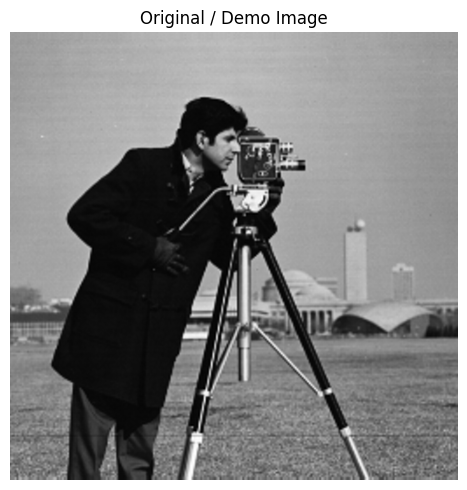

In [17]:
fp = Path("images") / "cameraman.png"

try:
    image = read_gray_image(fp) # have err in function read_gray_image and raise err to except in this scope
    print(f"อ่านไฟล์ภาพสำเร็จ: {fp}")
except FileNotFoundError as err:
    print(err)
    print("ใช้ภาพตัวอย่างที่สร้างจากโค้ดแทน")
    image = create_demo_image()

print("ขนาดภาพ:", image.shape)
show_images([image], ["Original / Demo Image"], figsize=(5, 5))


## 5. Kernel สำหรับประมาณค่า Gradient

ตัวตรวจจับขอบแบบพื้นฐานมักใช้ kernel 2 ตัว

- `Kx` ตรวจการเปลี่ยนแปลงในแนวนอน จึงตอบสนองกับขอบแนวตั้งได้ดี
- `Ky` ตรวจการเปลี่ยนแปลงในแนวตั้ง จึงตอบสนองกับขอบแนวนอนได้ดี

Prewitt และ Sobel คล้ายกันมาก ต่างกันที่ Sobel ให้น้ำหนักแถว/คอลัมน์กลางมากกว่า ทำให้ผลลัพธ์มักทนต่อ noise ได้ดีกว่าเล็กน้อย


In [18]:
prewitt_kx = np.array([[-1, 0, 1],
                       [-1, 0, 1],
                       [-1, 0, 1]], dtype=np.float32)

prewitt_ky = np.array([[-1, -1, -1],
                       [ 0,  0,  0],
                       [ 1,  1,  1]], dtype=np.float32)

sobel_kx = np.array([[-1, 0, 1],
                     [-2, 0, 2],
                     [-1, 0, 1]], dtype=np.float32)

sobel_ky = np.array([[-1, -2, -1],
                     [ 0,  0,  0],
                     [ 1,  2,  1]], dtype=np.float32)

print("Prewitt Kx:\n", prewitt_kx)
print("Prewitt Ky:\n", prewitt_ky)
print("Sobel Kx:\n", sobel_kx)
print("Sobel Ky:\n", sobel_ky)


Prewitt Kx:
 [[-1.  0.  1.]
 [-1.  0.  1.]
 [-1.  0.  1.]]
Prewitt Ky:
 [[-1. -1. -1.]
 [ 0.  0.  0.]
 [ 1.  1.  1.]]
Sobel Kx:
 [[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]
Sobel Ky:
 [[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]


## 6. เขียน Edge Operator เองแบบ Zero Padding

ก่อนใช้ฟังก์ชันสำเร็จรูป นักศึกษาควรเห็นขั้นตอนจริงของการเลื่อน kernel ไปบนภาพทีละตำแหน่ง แนวคิดนี้คือหัวใจของ convolution

ปัญหาที่ต้องจัดการคือบริเวณ “ขอบของภาพ” เช่นพิกเซลมุมซ้ายบน ไม่มีเพื่อนบ้านครบ 3x3 ถ้าไม่จัดการอะไรเลย เราจะคำนวณได้เฉพาะบริเวณด้านในและทิ้งขอบภาพไป วิธีง่ายสำหรับการเรียนคือ **zero padding** คือเติมค่า 0 รอบภาพก่อน 1 ชั้น สำหรับ kernel 3x3

ในฟังก์ชัน `edge_operator_meth(img, k)` ด้านล่าง

- `k=1` จะได้ kernel แบบ Prewitt
- `k=2` จะได้ kernel แบบ Sobel
- ไม่ใช้ `cv2.filter2D()` หรือ `cv2.Sobel()` เพื่อให้นักศึกษาเห็นขั้นตอนการคำนวณเอง


In [19]:
def edge_operator_meth(img, k=1):
    """คำนวณ edge magnitude ด้วย kernel 3x3 แบบเขียน convolution เอง

    k=1 คือ Prewitt, k=2 คือ Sobel
    ใช้ zero padding เพื่อให้คำนวณได้ครบทุกพิกเซลรวมถึงขอบภาพ
    """
    f = img.astype(np.float32)
    out = np.zeros_like(f, dtype=np.float32)

    mask_gx = np.array([[-1, 0, 1],
                        [-k, 0, k],
                        [-1, 0, 1]], dtype=np.float32)

    mask_gy = np.array([[-1, -k, -1],
                        [ 0,  0,  0],
                        [ 1,  k,  1]], dtype=np.float32)

    bd = mask_gx.shape[0] // 2
    padded = np.pad(f, pad_width=bd, mode="constant", constant_values=0)
    m, n = f.shape

    for i in range(m):
        for j in range(n):
            sub_f = padded[i : i + 2 * bd + 1, j : j + 2 * bd + 1]
            gx = np.multiply(sub_f, mask_gx).sum()
            gy = np.multiply(sub_f, mask_gy).sum()
            out[i, j] = np.sqrt(gx**2 + gy**2)

    out = np.clip(out, 0, 255)
    return out.astype(np.uint8)


def gradient_edge(img, kernel_x, kernel_y):
    """คำนวณด้วย OpenCV สำหรับเทียบกับวิธีเขียนเอง"""
    img_float = img.astype(np.float32)
    gx = cv2.filter2D(img_float, cv2.CV_32F, kernel_x, borderType=cv2.BORDER_CONSTANT) # ได้ทั้งภาพเลย
    gy = cv2.filter2D(img_float, cv2.CV_32F, kernel_y, borderType=cv2.BORDER_CONSTANT) # ได้ทั้งภาพเลย
    magnitude = cv2.magnitude(gx, gy) # เราเลยต้องใช้ magnitude 
    return normalize_to_uint8(gx), normalize_to_uint8(gy), normalize_to_uint8(magnitude)


### ตัวอย่าง Zero Padding แบบย่อ

ตัวอย่างนี้ใช้เมทริกซ์ 3x3 ขนาดเล็ก เพื่อให้เห็นว่าเมื่อเติม zero padding แล้ว ภาพจะใหญ่ขึ้นเป็น 5x5 และ kernel 3x3 สามารถวางทับพิกเซลเดิมได้ครบทุกตำแหน่ง


In [20]:
small_img = np.array([[10, 10, 10],
                      [10, 80, 10],
                      [10, 10, 10]], dtype=np.uint8)

padded_small_img = np.pad(small_img, pad_width=1, mode="constant", constant_values=0)

print("ภาพเดิม 3x3:\n", small_img)
print("หลังเติม zero padding เป็น 5x5:\n", padded_small_img)


ภาพเดิม 3x3:
 [[10 10 10]
 [10 80 10]
 [10 10 10]]
หลังเติม zero padding เป็น 5x5:
 [[ 0  0  0  0  0]
 [ 0 10 10 10  0]
 [ 0 10 80 10  0]
 [ 0 10 10 10  0]
 [ 0  0  0  0  0]]


## 7. Prewitt Operator

Prewitt เป็นวิธีง่ายและตรงไปตรงมา เหมาะสำหรับอธิบายหลักการเริ่มต้น เพราะ kernel ใช้ค่าน้ำหนักเท่า ๆ กันในทิศที่ต้องการวัดการเปลี่ยนแปลง

ในตัวอย่างนี้ใช้ `edge_operator_meth(image, k=1)` ซึ่งเป็นโค้ดที่เขียน convolution เองแบบ zero padding ไม่ได้เรียก `cv2.filter2D()`


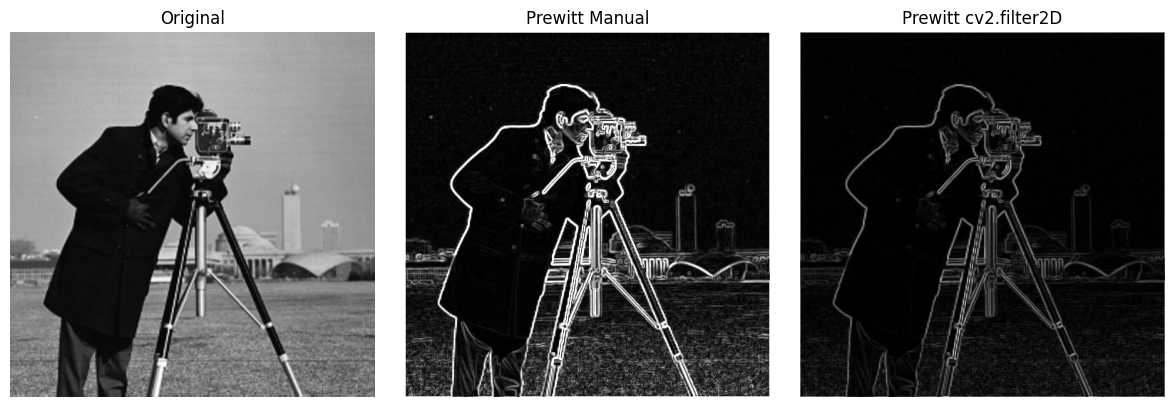

In [21]:
prewitt_edge_manual = edge_operator_meth(image, k=1)
_, _, prewitt_edge_cv = gradient_edge(image, prewitt_kx, prewitt_ky)

show_images(
    [image, prewitt_edge_manual, prewitt_edge_cv],
    ["Original", "Prewitt Manual", "Prewitt cv2.filter2D"],
    figsize=(12, 4),
)


## 8. Sobel Operator

Sobel ใช้ kernel ที่ให้น้ำหนักตำแหน่งกลางมากกว่า Prewitt เช่น `[-1, 0, 1]` กลายเป็น `[-2, 0, 2]` ในแนวกลาง ผลคือขอบที่ได้มักชัดและเสถียรกว่าเล็กน้อย

ในฟังก์ชันที่เขียนเอง ใช้ `k=2` เพื่อเปลี่ยน kernel จาก Prewitt ให้เป็น Sobel โดยไม่ต้องเขียนโค้ดซ้ำ


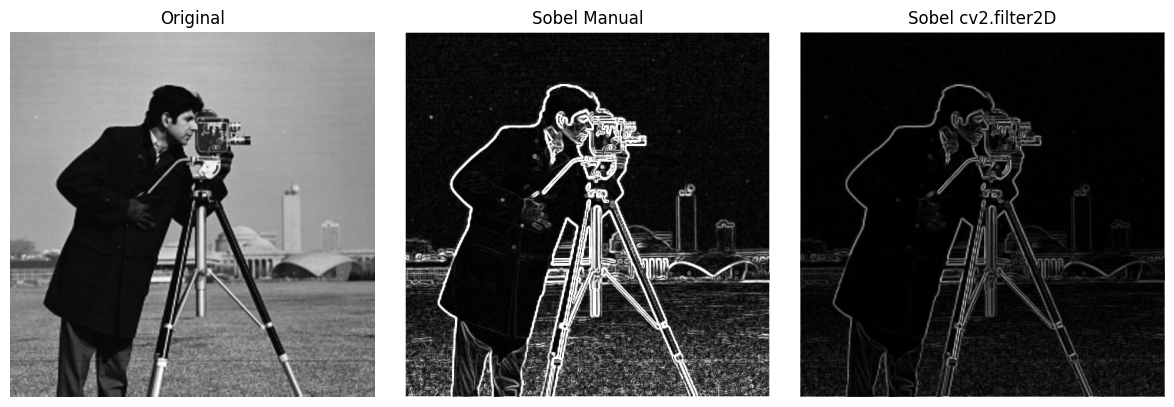

In [22]:
sobel_edge_manual = edge_operator_meth(image, k=2)
_, _, sobel_edge_cv = gradient_edge(image, sobel_kx, sobel_ky)

show_images(
    [image, sobel_edge_manual, sobel_edge_cv],
    ["Original", "Sobel Manual", "Sobel cv2.filter2D"],
    figsize=(12, 4),
)


## 9. เปรียบเทียบ Prewitt และ Sobel จากโค้ดที่เขียนเอง

ทั้งสองวิธีตรวจจับขอบจากขนาดของ gradient เหมือนกัน ดังนั้นโครงสร้างของผลลัพธ์จะคล้ายกันมาก ความแตกต่างสำคัญอยู่ที่ kernel ของ Sobel ให้ความสำคัญกับพิกเซลแถว/คอลัมน์กลางมากกว่า

สังเกตว่าเราใช้ฟังก์ชันเดียวกัน แต่เปลี่ยนค่า `k` เท่านั้น ทำให้นักศึกษาเห็นความสัมพันธ์ระหว่าง Prewitt และ Sobel ได้ชัดเจน


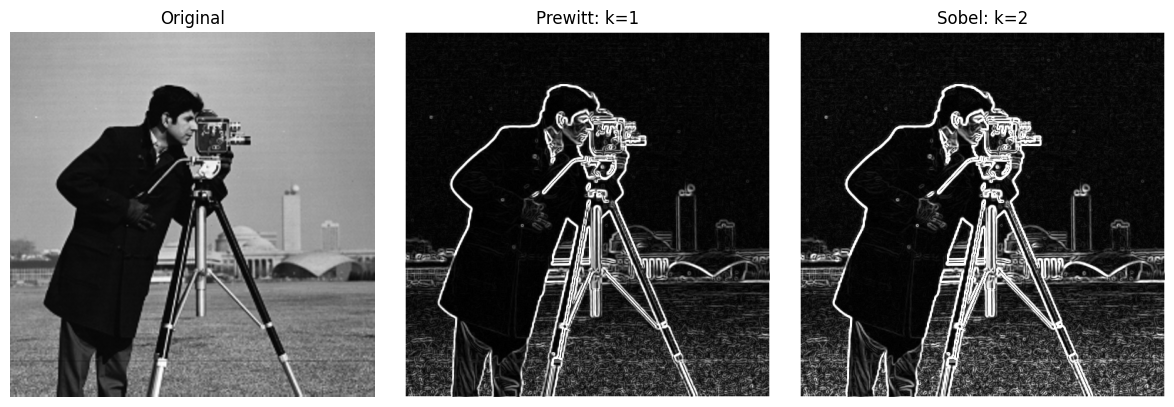

In [23]:
show_images(
    [image, prewitt_edge_manual, sobel_edge_manual],
    ["Original", "Prewitt: k=1", "Sobel: k=2"],
    figsize=(12, 4),
)


## 10. Canny Edge Detector

Canny เป็นวิธีตรวจจับขอบที่นิยมมาก เพราะให้ขอบที่บางและต่อเนื่องกว่า gradient ธรรมดา โดยแนวคิดหลักประกอบด้วย

1. ลด noise ด้วย Gaussian blur
2. คำนวณ gradient และทิศทางของขอบ
3. ทำ non-maximum suppression เพื่อทำให้เส้นขอบบางลง
4. ใช้ double threshold แยกขอบที่ชัดเจนและขอบที่ยังไม่แน่นอน
5. ใช้ hysteresis ติดตามขอบที่เชื่อมกับขอบที่ชัดเจน

พารามิเตอร์สำคัญคือ `threshold1` และ `threshold2` ถ้าตั้งต่ำเกินไปจะเจอขอบจำนวนมากรวมถึง noise ถ้าตั้งสูงเกินไปอาจสูญเสียขอบที่สำคัญ


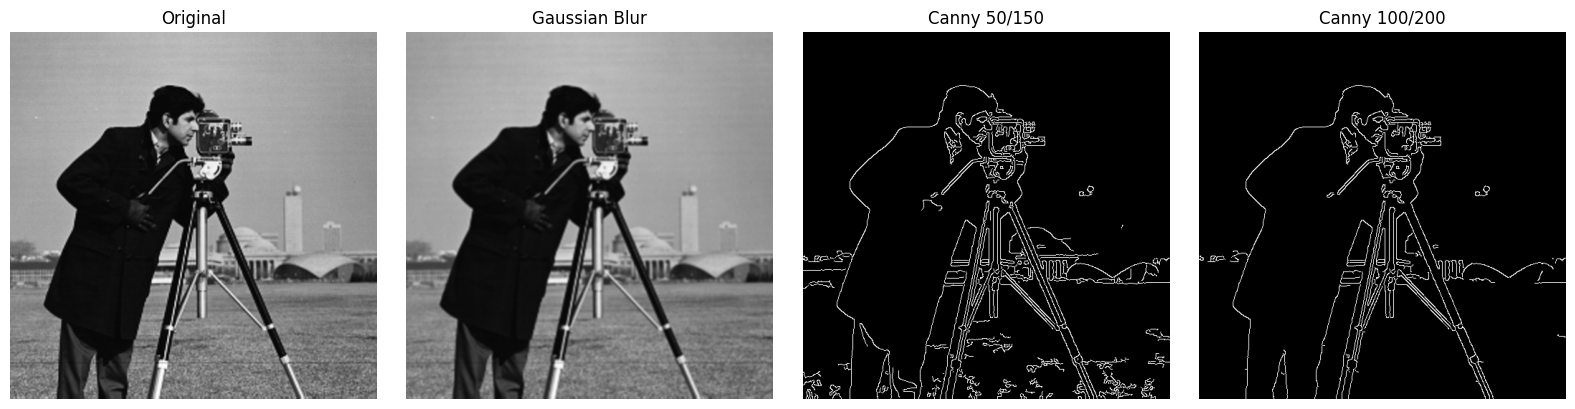

In [24]:
blurred = cv2.GaussianBlur(image, (5, 5), 1.0)
canny_50_150 = cv2.Canny(blurred, threshold1=50, threshold2=150)
canny_100_200 = cv2.Canny(blurred, threshold1=100, threshold2=200)

show_images(
    [image, blurred, canny_50_150, canny_100_200],
    ["Original", "Gaussian Blur", "Canny 50/150", "Canny 100/200"],
    figsize=(16, 4),
)


## 11. สรุปสำหรับนักศึกษา

- ขอบภาพคือบริเวณที่ค่าความสว่างเปลี่ยนเร็ว
- Prewitt และ Sobel ใช้ convolution kernel เพื่อประมาณ `Gx` และ `Gy`
- การเขียน convolution เองช่วยให้เห็นว่า kernel ถูกเลื่อนครอบภาพทีละตำแหน่งอย่างไร
- Zero padding ช่วยให้คำนวณผลลัพธ์ได้ครบทุกพิกเซล รวมถึงบริเวณขอบภาพ
- ขนาดของ gradient `|G|` ใช้บอกความแรงของขอบ
- Sobel มักใช้บ่อยกว่า Prewitt เพราะให้ผลเสถียรกว่าเล็กน้อยและมีฟังก์ชันใน OpenCV
- Canny เป็นวิธีหลายขั้นตอนที่ให้เส้นขอบบางและใช้งานจริงได้ดี
- ทุกครั้งที่อ่านภาพด้วย `cv2.imread()` ควรตรวจสอบว่าอ่านสำเร็จหรือไม่ เพื่อป้องกัน error ที่ตามมา เช่นเรียก `.shape` กับค่า `None`
- `create_demo_image()` เป็นภาพสำรองสำหรับการสอน เมื่อยังไม่มีไฟล์ภาพจริงให้ทดลอง

**แบบฝึกหัดสั้น ๆ**

1. เปลี่ยนค่า `threshold1` และ `threshold2` ของ Canny แล้วสังเกตผลลัพธ์
2. ลองเปลี่ยนขนาด Gaussian blur จาก `(5, 5)` เป็น `(3, 3)` หรือ `(7, 7)`
3. นำภาพของตนเองมาใส่ในโฟลเดอร์ `images` แล้วเปลี่ยนค่า `fp` ให้ตรงกับชื่อไฟล์
4. ทดลองแก้ค่า `k` ใน `edge_operator_meth(image, k)` แล้วอธิบายว่าขอบที่ได้เปลี่ยนอย่างไร


## 12. Zero Padding

**Zero padding** คือการเติมค่า 0 รอบขอบของภาพหรือเมทริกซ์ก่อนนำ kernel ไปคำนวณ convolution จุดประสงค์สำคัญคือทำให้เราสามารถวาง kernel ครอบพิกเซลบริเวณขอบภาพได้ครบเหมือนพิกเซลด้านใน

ถ้าใช้ kernel ขนาด 3x3 เรามักเติม padding รอบภาพ 1 ชั้น เพราะ kernel มีรัศมีจากจุดกึ่งกลางออกไปด้านละ 1 ช่อง ถ้าใช้ kernel ขนาด 5x5 จะเติม padding 2 ชั้น

**หลักการ**

- ภาพเดิมมีขนาด `m x n`
- เติมค่า 0 รอบภาพจำนวน `pad` ชั้น
- ภาพหลัง padding จะมีขนาด `(m + 2pad) x (n + 2pad)`
- ใช้ภาพที่เติม padding แล้วเป็น “พื้นที่ช่วยคำนวณ”
- ผลลัพธ์สุดท้ายควรเก็บเฉพาะตำแหน่งที่ตรงกับภาพเดิม จึงได้ output ขนาด `m x n`

**แนวปฏิบัติในการใช้**

- ใช้ zero padding เมื่อต้องการให้ output มีขนาดเท่ากับ input
- ไม่ถือว่า padding เป็นข้อมูลจริงของภาพ แต่เป็นค่าที่เติมชั่วคราวเพื่อให้คำนวณบริเวณขอบได้
- หลัง padding สามารถตัดกลับเป็นขนาดเดิมด้วย slicing เช่น `padded[pad:-pad, pad:-pad]`
- ในงาน convolution จริง นิยมสร้าง `output = np.zeros_like(input)` แล้วคำนวณทีละตำแหน่งลงใน output ที่มีขนาดเท่า input ตั้งแต่ต้น
- ควรระวังว่า padding ด้วย 0 อาจทำให้บริเวณขอบภาพเกิดค่าความต่างสูงกว่าความเป็นจริงในบางกรณี เพราะค่า 0 อาจต่างจากค่าพิกเซลจริงมาก
- ใน OpenCV ถ้าต้องการพฤติกรรมคล้าย zero padding ให้กำหนด `borderType=cv2.BORDER_CONSTANT`


In [25]:
matrix = np.array([[1, 2, 3],
                   [4, 5, 6],
                   [7, 8, 9]], dtype=np.float32)

kernel = np.array([[1, 0, -1],
                   [1, 0, -1],
                   [1, 0, -1]], dtype=np.float32)

pad = kernel.shape[0] // 2
padded_matrix = np.pad(matrix, pad_width=pad, mode="constant", constant_values=0)

print("matrix เดิม:")
print(matrix)
print("shape:", matrix.shape)

print("\nmatrix หลังทำ zero padding:")
print(padded_matrix)
print("shape:", padded_matrix.shape)

recovered_matrix = padded_matrix[pad:-pad, pad:-pad]
print("\nตัด padding ออก เพื่อกลับมาเป็น matrix ขนาดเดิม:")
print(recovered_matrix)
print("shape:", recovered_matrix.shape)

# คำนวณ convolution ทุกตำแหน่ง โดยให้ output มีขนาดเท่า matrix เดิม
output = np.zeros_like(matrix, dtype=np.float32)

for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        sub_matrix = padded_matrix[i : i + kernel.shape[0], j : j + kernel.shape[1]]
        output[i, j] = np.multiply(sub_matrix, kernel).sum()

print("\nผลลัพธ์ convolution หลังใช้ zero padding:")
print(output)
print("shape:", output.shape)

# แสดงรายละเอียดหนึ่งตำแหน่ง เพื่อให้นักศึกษาเห็นวิธีคิด
i, j = 0, 0
sub_matrix = padded_matrix[i : i + kernel.shape[0], j : j + kernel.shape[1]]
value = np.multiply(sub_matrix, kernel).sum()

print("\nบริเวณ 3x3 ที่ kernel ครอบตำแหน่งซ้ายบนของ matrix เดิม:")
print(sub_matrix)
print("\nผลคูณทีละตำแหน่งระหว่าง sub_matrix กับ kernel:")
print(sub_matrix * kernel)
print("\nผลรวมที่ตำแหน่งซ้ายบน =", value)


matrix เดิม:
[[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]
shape: (3, 3)

matrix หลังทำ zero padding:
[[0. 0. 0. 0. 0.]
 [0. 1. 2. 3. 0.]
 [0. 4. 5. 6. 0.]
 [0. 7. 8. 9. 0.]
 [0. 0. 0. 0. 0.]]
shape: (5, 5)

ตัด padding ออก เพื่อกลับมาเป็น matrix ขนาดเดิม:
[[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]
shape: (3, 3)

ผลลัพธ์ convolution หลังใช้ zero padding:
[[ -7.  -4.   7.]
 [-15.  -6.  15.]
 [-13.  -4.  13.]]
shape: (3, 3)

บริเวณ 3x3 ที่ kernel ครอบตำแหน่งซ้ายบนของ matrix เดิม:
[[0. 0. 0.]
 [0. 1. 2.]
 [0. 4. 5.]]

ผลคูณทีละตำแหน่งระหว่าง sub_matrix กับ kernel:
[[ 0.  0. -0.]
 [ 0.  0. -2.]
 [ 0.  0. -5.]]

ผลรวมที่ตำแหน่งซ้ายบน = -7.0
